In [70]:
import pandas as pd

# Read the transformed mesonet data and UHI index training data
mesonet_transformed = pd.read_csv('mesonet_transformed.csv')
training_latlong = pd.read_csv('Training_data_uhi_index.csv')


In [71]:
mesonet_transformed.columns

Index(['Datetime', 'Lat_brx', 'Long_brx', 'temp_C_brx', 'humidity_perc_brx',
       'windspeed_ms_brx', 'winddir_deg_brx', 'flux_wm2_brx', 'lat_mhtn',
       'long_mhtn', 'temp_C_mhtn', 'humidity_perc_mhtn', 'windspeed_ms_mhtn',
       'winddir_deg_mhtn', 'flux_wm2_mhtn'],
      dtype='object')

C:\Users\Asad\AppData\Local\Temp\ipykernel_2976\321227667.py:5: FutureWarning: Parsed string "2021-07-24 06:00:00 EDT" included an un-recognized timezone "EDT". Dropping unrecognized timezones is deprecated; in a future version this will raise. Instead pass the string without the timezone, then use .tz_localize to convert to a recognized timezone.
  mesonet_transformed['Datetime'] = pd.to_datetime(mesonet_transformed['Datetime'])


<Figure size 1500x1000 with 0 Axes>

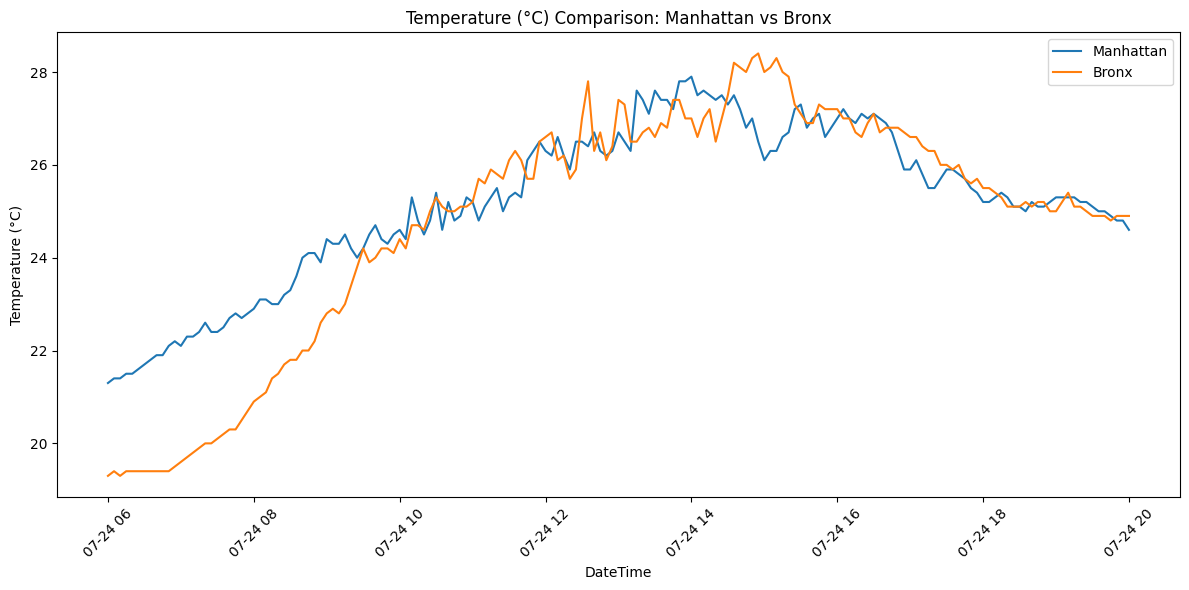

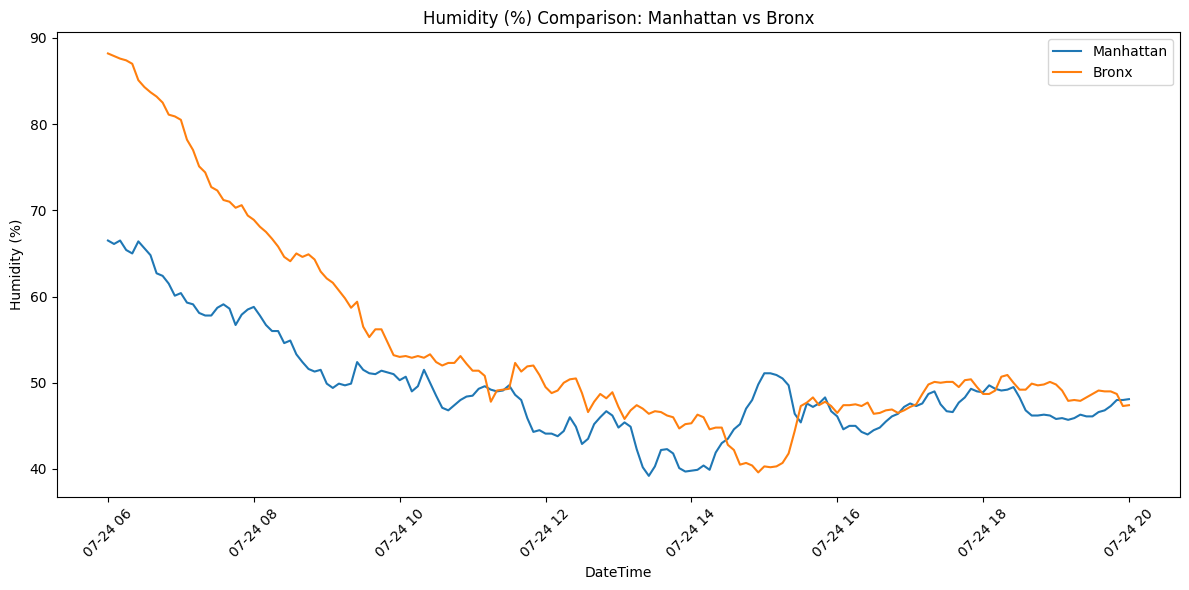

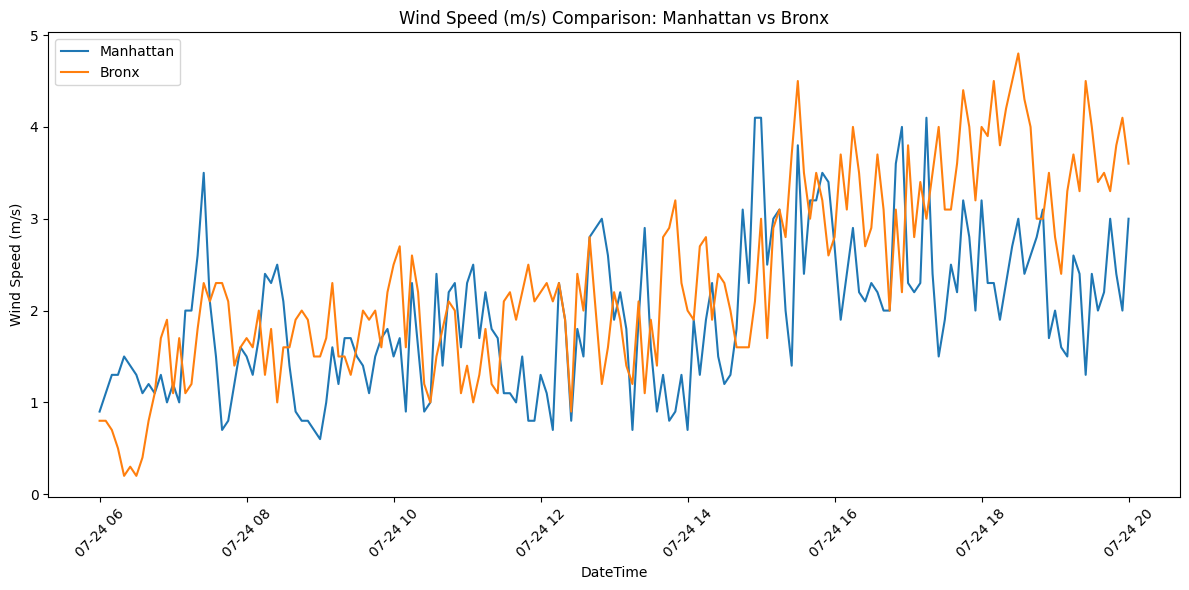

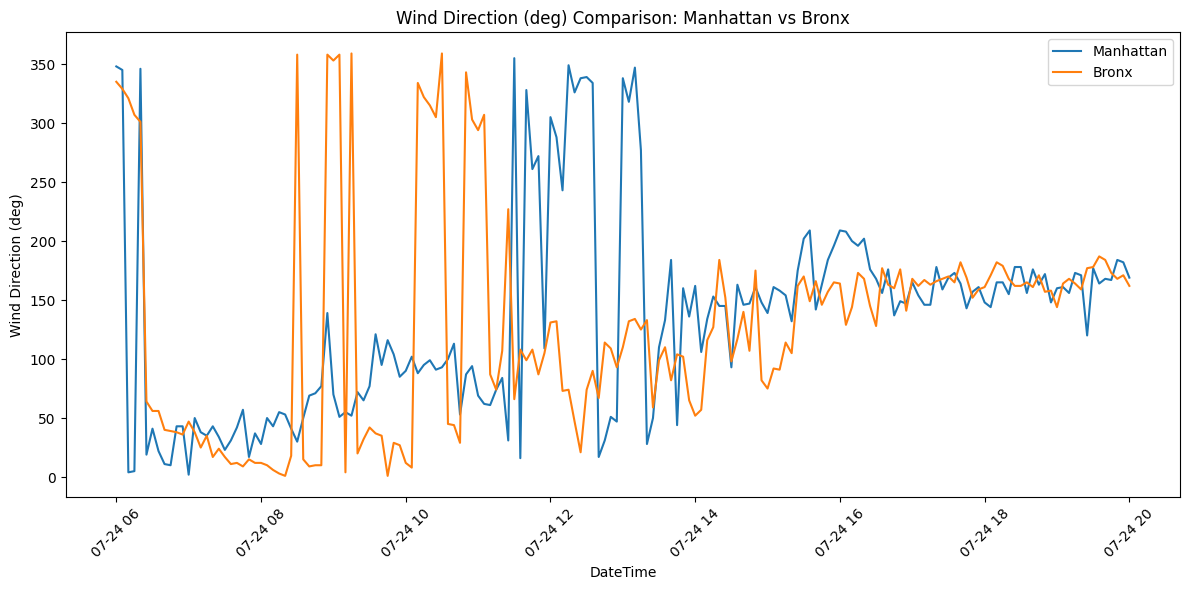

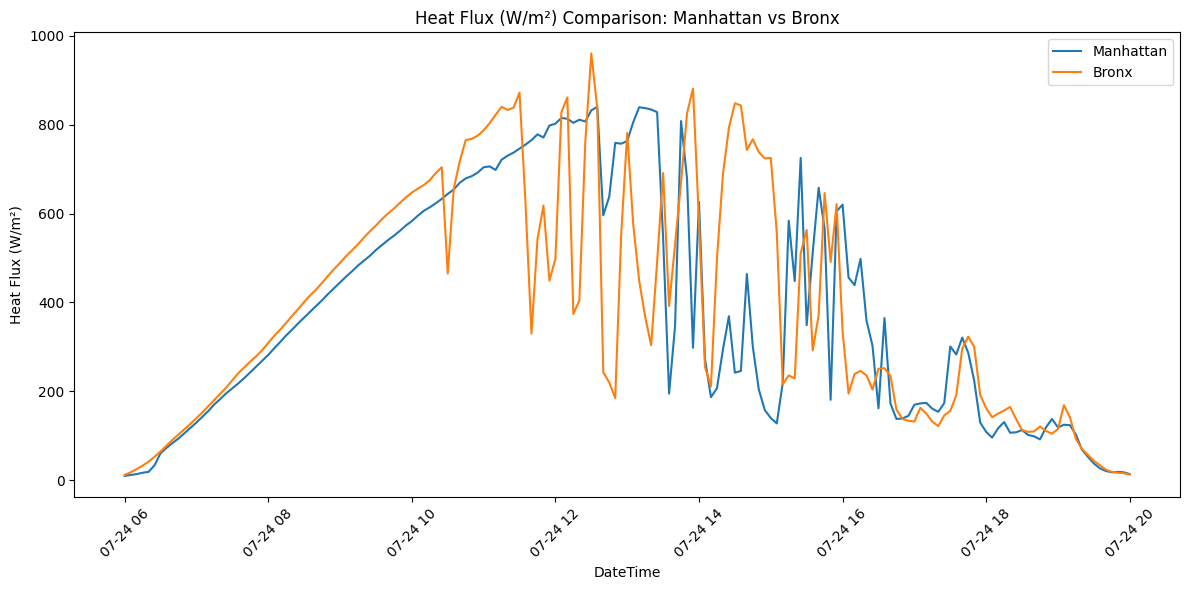

In [72]:
import matplotlib.pyplot as plt
import seaborn as sns

# Convert datetime column to datetime type if not already
mesonet_transformed['Datetime'] = pd.to_datetime(mesonet_transformed['Datetime'])

# Set up the figure size
plt.figure(figsize=(15, 10))

# Create pairs of Manhattan and Bronx columns
column_pairs = {
    'Temperature (°C)': ('temp_C_mhtn', 'temp_C_brx'),
    'Humidity (%)': ('humidity_perc_mhtn', 'humidity_perc_brx'),
    'Wind Speed (m/s)': ('windspeed_ms_mhtn', 'windspeed_ms_brx'),
    'Wind Direction (deg)': ('winddir_deg_mhtn', 'winddir_deg_brx'),
    'Heat Flux (W/m²)': ('flux_wm2_mhtn', 'flux_wm2_brx')
}

# Plot each pair of measurements
for title, (mhtn_col, brx_col) in column_pairs.items():
    plt.figure(figsize=(12, 6))
    plt.plot(mesonet_transformed['Datetime'], mesonet_transformed[mhtn_col], label='Manhattan')
    plt.plot(mesonet_transformed['Datetime'], mesonet_transformed[brx_col], label='Bronx')
    plt.title(f'{title} Comparison: Manhattan vs Bronx')
    plt.xlabel('DateTime')
    plt.ylabel(title)
    plt.xticks(rotation=45)
    plt.legend()
    plt.tight_layout()
    plt.show()


<Figure size 1500x1000 with 0 Axes>

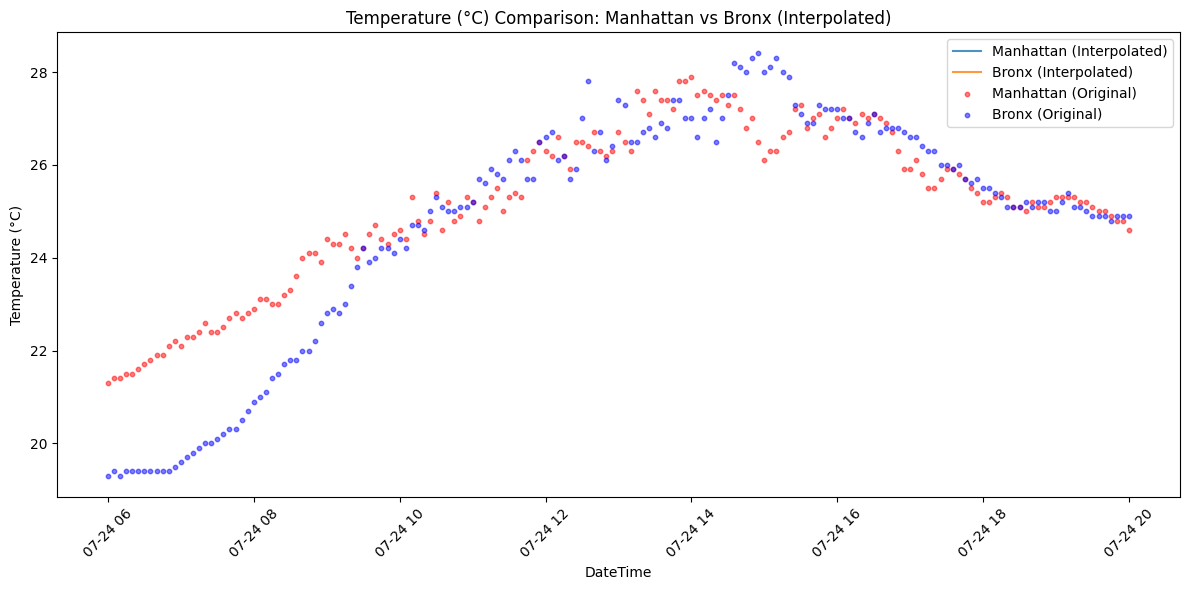

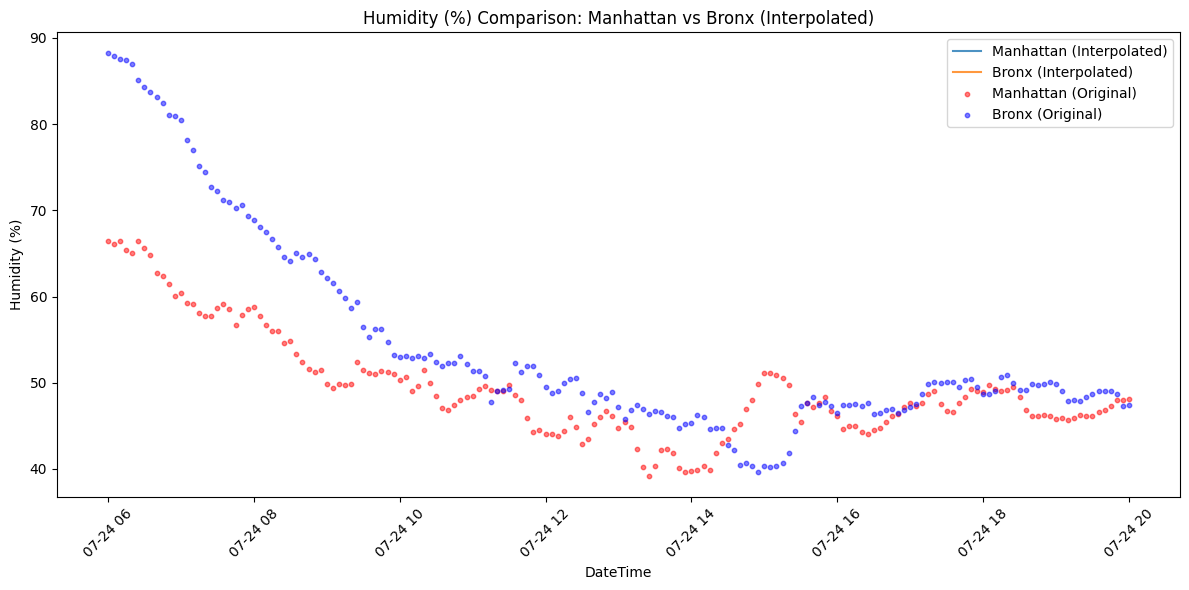

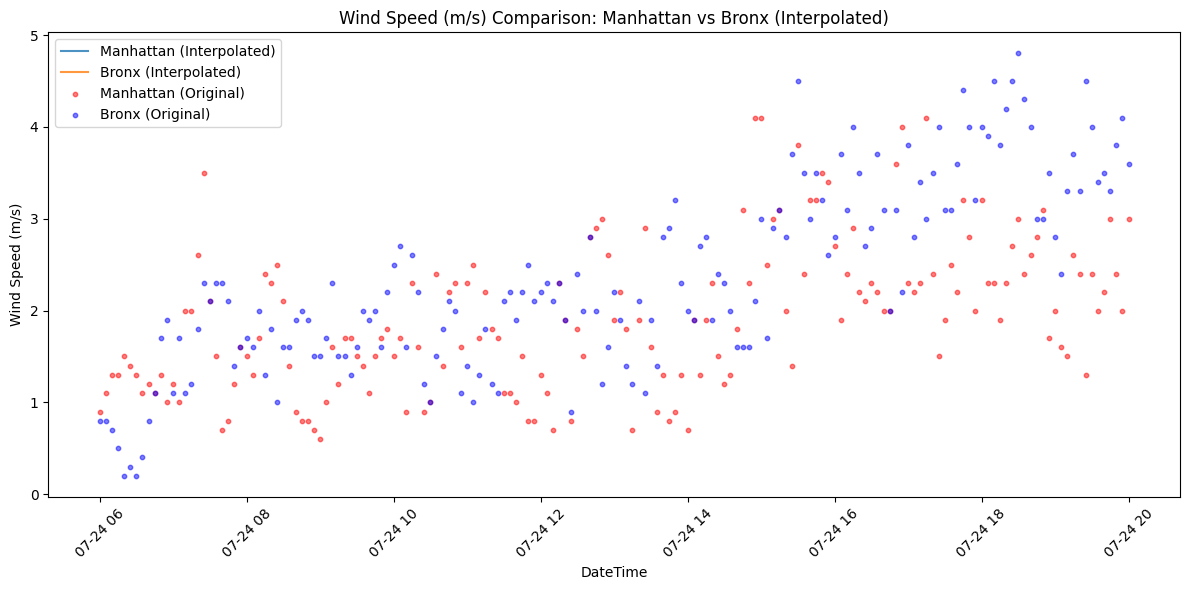

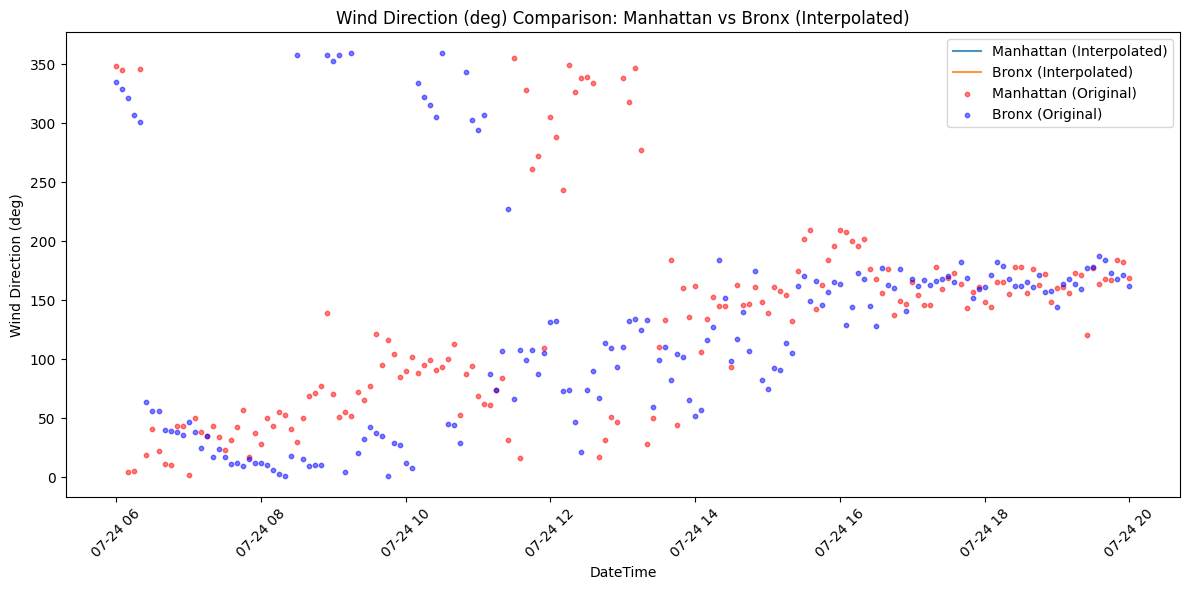

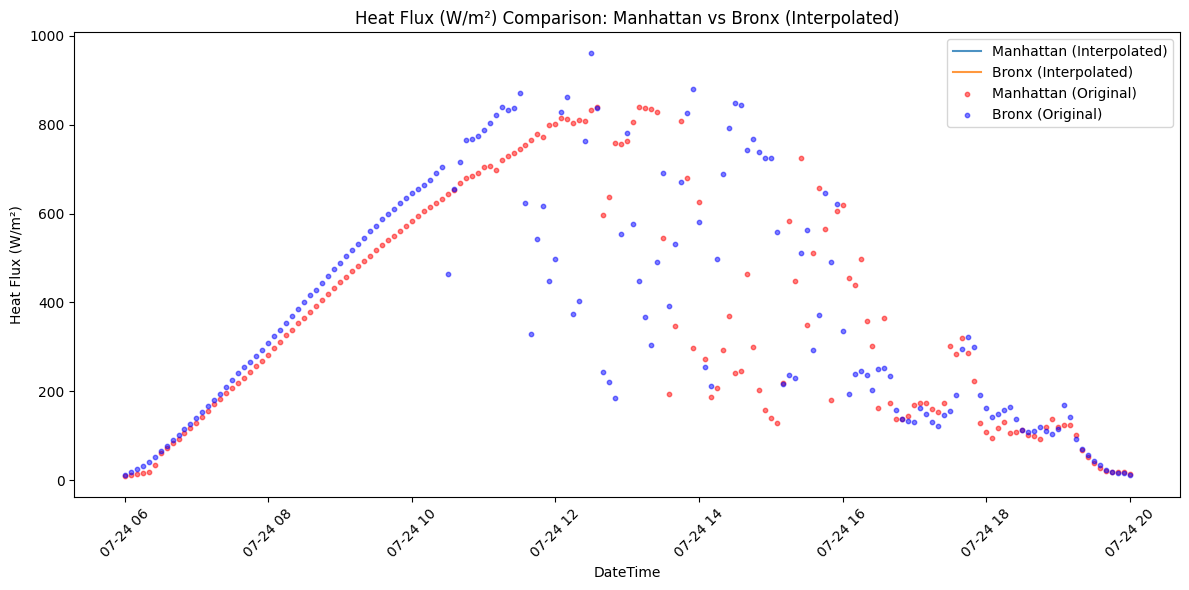

In [73]:
# Create a complete datetime range at minute level
date_range = pd.date_range(start=mesonet_transformed['Datetime'].min(),
                          end=mesonet_transformed['Datetime'].max(),
                          freq='1min')

# Create a new dataframe with the complete datetime range
mesonet_interpolated = pd.DataFrame({'Datetime': date_range})

# Set datetime as index for both dataframes to facilitate interpolation
mesonet_transformed.set_index('Datetime', inplace=True)
mesonet_interpolated.set_index('Datetime', inplace=True)

# Interpolate all numeric columns
numeric_columns = mesonet_transformed.select_dtypes(include=['float64', 'int64']).columns
for col in numeric_columns:
    mesonet_interpolated[col] = mesonet_transformed[col].interpolate(method='linear')

# Reset index to make Datetime a column again
mesonet_interpolated.reset_index(inplace=True)
mesonet_transformed.reset_index(inplace=True)

# Plot the interpolated data
plt.figure(figsize=(15, 10))

for title, (mhtn_col, brx_col) in column_pairs.items():
    plt.figure(figsize=(12, 6))
    plt.plot(mesonet_interpolated['Datetime'], mesonet_interpolated[mhtn_col], 
             label='Manhattan (Interpolated)', alpha=0.8)
    plt.plot(mesonet_interpolated['Datetime'], mesonet_interpolated[brx_col], 
             label='Bronx (Interpolated)', alpha=0.8)
    plt.scatter(mesonet_transformed['Datetime'], mesonet_transformed[mhtn_col], 
                color='red', s=10, alpha=0.5, label='Manhattan (Original)')
    plt.scatter(mesonet_transformed['Datetime'], mesonet_transformed[brx_col], 
                color='blue', s=10, alpha=0.5, label='Bronx (Original)')
    plt.title(f'{title} Comparison: Manhattan vs Bronx (Interpolated)')
    plt.xlabel('DateTime')
    plt.ylabel(title)
    plt.xticks(rotation=45)
    plt.legend()
    plt.tight_layout()
    plt.show()


In [74]:
mesonet_interpolated.Datetime[(mesonet_interpolated.Datetime.dt.hour == 15)]

540   2021-07-24 15:00:00
541   2021-07-24 15:01:00
542   2021-07-24 15:02:00
543   2021-07-24 15:03:00
544   2021-07-24 15:04:00
545   2021-07-24 15:05:00
546   2021-07-24 15:06:00
547   2021-07-24 15:07:00
548   2021-07-24 15:08:00
549   2021-07-24 15:09:00
550   2021-07-24 15:10:00
551   2021-07-24 15:11:00
552   2021-07-24 15:12:00
553   2021-07-24 15:13:00
554   2021-07-24 15:14:00
555   2021-07-24 15:15:00
556   2021-07-24 15:16:00
557   2021-07-24 15:17:00
558   2021-07-24 15:18:00
559   2021-07-24 15:19:00
560   2021-07-24 15:20:00
561   2021-07-24 15:21:00
562   2021-07-24 15:22:00
563   2021-07-24 15:23:00
564   2021-07-24 15:24:00
565   2021-07-24 15:25:00
566   2021-07-24 15:26:00
567   2021-07-24 15:27:00
568   2021-07-24 15:28:00
569   2021-07-24 15:29:00
570   2021-07-24 15:30:00
571   2021-07-24 15:31:00
572   2021-07-24 15:32:00
573   2021-07-24 15:33:00
574   2021-07-24 15:34:00
575   2021-07-24 15:35:00
576   2021-07-24 15:36:00
577   2021-07-24 15:37:00
578   2021-0

In [75]:
training_latlong.columns

Index(['Longitude', 'Latitude', 'datetime', 'UHI Index',
       'nearest_building_count_10m', 'nearest_building_count_50m',
       'nearest_building_count_100m', 'nearest_building_count_500m'],
      dtype='object')

In [76]:
import numpy as np

# Calculate distances to both stations for each point
def calculate_distance(lat1, lon1, lat2, lon2):
    # Using Haversine formula
    R = 6371  # Earth's radius in km
    
    lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1, lat2, lon2])
    
    dlat = lat2 - lat1
    dlon = lon2 - lon1
    
    a = np.sin(dlat/2)**2 + np.cos(lat1) * np.cos(lat2) * np.sin(dlon/2)**2
    c = 2 * np.arcsin(np.sqrt(a))
    
    return R * c

# Get Manhattan and Bronx station coordinates from mesonet data
mhtn_lat = mesonet_transformed['lat_mhtn'].iloc[0]
mhtn_lon = mesonet_transformed['long_mhtn'].iloc[0]
brx_lat = mesonet_transformed['Lat_brx'].iloc[0]
brx_lon = mesonet_transformed['Long_brx'].iloc[0]

# Calculate distances to both stations
training_latlong['dist_to_mhtn'] = training_latlong.apply(
    lambda row: calculate_distance(row['Latitude'], row['Longitude'], mhtn_lat, mhtn_lon), 
    axis=1
)

training_latlong['dist_to_brx'] = training_latlong.apply(
    lambda row: calculate_distance(row['Latitude'], row['Longitude'], brx_lat, brx_lon),
    axis=1
)

# Assign nearest station based on minimum distance
training_latlong['nearest_station'] = training_latlong.apply(
    lambda row: 'mhtn' if row['dist_to_mhtn'] < row['dist_to_brx'] else 'bronx',
    axis=1
)

# Drop the distance columns as they were only needed for calculation
training_latlong.drop(['dist_to_mhtn', 'dist_to_brx'], axis=1, inplace=True)

training_latlong.head()

,Longitude,Latitude,datetime,UHI Index,nearest_building_count_10m,nearest_building_count_50m,nearest_building_count_100m,nearest_building_count_500m,nearest_station
0,-73.909167,40.813107,24-07-2021 15:53,1.030289,0,0,5,100,bronx
1,-73.909187,40.813045,24-07-2021 15:53,1.030289,0,0,5,100,bronx
2,-73.909215,40.812978,24-07-2021 15:53,1.023798,0,0,4,100,bronx
3,-73.909242,40.812908,24-07-2021 15:53,1.023798,0,0,4,100,bronx
4,-73.909257,40.812845,24-07-2021 15:53,1.021634,0,0,4,100,bronx


In [77]:
# Display count of points nearest to each station
len(training_latlong['datetime'].unique())


59

In [85]:
# Convert datetime to minutes format for both dataframes
mesonet_interpolated['DateTime_Minutes'] = pd.to_datetime(mesonet_interpolated['Datetime']).dt.strftime('%Y-%m-%d %H:%M')
training_latlong['DateTime_Minutes'] = pd.to_datetime(training_latlong['datetime']).dt.strftime('%Y-%m-%d %H:%M')

# Create separate dataframes for Manhattan and Bronx from mesonet data
mhtn_weather = mesonet_interpolated[['DateTime_Minutes', 'temp_C_mhtn', 'humidity_perc_mhtn', 
                                   'windspeed_ms_mhtn', 'winddir_deg_mhtn', 'flux_wm2_mhtn']]
mhtn_weather['Station'] = 'mhtn'
mhtn_weather.columns = ['DateTime_Minutes', 'Temperature', 'Humidity', 'WindSpeed', 
                       'WindDirection', 'SolarFlux', 'Station']

brx_weather = mesonet_interpolated[['DateTime_Minutes', 'temp_C_brx', 'humidity_perc_brx',
                                  'windspeed_ms_brx', 'winddir_deg_brx', 'flux_wm2_brx']]
brx_weather['Station'] = 'bronx'
brx_weather.columns = ['DateTime_Minutes', 'Temperature', 'Humidity', 'WindSpeed',
                      'WindDirection', 'SolarFlux', 'Station']

# Combine weather station data
weather_combined = pd.concat([mhtn_weather, brx_weather])

# Drop rows with null weather features
weather_combined = weather_combined.dropna(subset=['Temperature', 'Humidity', 'WindSpeed', 
                                                 'WindDirection', 'SolarFlux'])

# Calculate average UHI for each timestamp and station
uhi_data = training_latlong.groupby(['DateTime_Minutes', 'nearest_station'])['UHI Index'].mean().reset_index()
uhi_data.columns = ['DateTime_Minutes', 'Station', 'UHI Index']

# Merge weather and average UHI data
combined_df = pd.merge(weather_combined, uhi_data,
                      on=['DateTime_Minutes', 'Station'],
                      how='right')  # Changed to inner join to keep only matched rows

# Sort by DateTime and Station
combined_df = combined_df.sort_values(['DateTime_Minutes', 'Station'])

# Display first few rows of combined dataset
combined_df.head()

C:\Users\Asad\AppData\Local\Temp\ipykernel_2976\174327055.py:3: UserWarning: Parsing dates in %d-%m-%Y %H:%M format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  training_latlong['DateTime_Minutes'] = pd.to_datetime(training_latlong['datetime']).dt.strftime('%Y-%m-%d %H:%M')
C:\Users\Asad\AppData\Local\Temp\ipykernel_2976\174327055.py:8: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  mhtn_weather['Station'] = 'mhtn'
C:\Users\Asad\AppData\Local\Temp\ipykernel_2976\174327055.py:14: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas

,DateTime_Minutes,Temperature,Humidity,WindSpeed,WindDirection,SolarFlux,Station,UHI Index
0,2021-07-24 15:01,NaN,NaN,NaN,NaN,NaN,mhtn,0.990035
1,2021-07-24 15:02,NaN,NaN,NaN,NaN,NaN,mhtn,1.000132
2,2021-07-24 15:03,NaN,NaN,NaN,NaN,NaN,mhtn,1.021004
3,2021-07-24 15:04,NaN,NaN,NaN,NaN,NaN,mhtn,0.998338
4,2021-07-24 15:05,26.3,51.1,2.5,161.0,128.0,mhtn,1.000146


In [86]:
len(uhi_data)

112

In [87]:
# Filter out rows where UHI Index is NA
combined_df = combined_df.dropna(subset=['UHI Index'])

# Display first few rows of filtered dataset
combined_df.head()


,DateTime_Minutes,Temperature,Humidity,WindSpeed,WindDirection,SolarFlux,Station,UHI Index
0,2021-07-24 15:01,NaN,NaN,NaN,NaN,NaN,mhtn,0.990035
1,2021-07-24 15:02,NaN,NaN,NaN,NaN,NaN,mhtn,1.000132
2,2021-07-24 15:03,NaN,NaN,NaN,NaN,NaN,mhtn,1.021004
3,2021-07-24 15:04,NaN,NaN,NaN,NaN,NaN,mhtn,0.998338
4,2021-07-24 15:05,26.3,51.1,2.5,161.0,128.0,mhtn,1.000146


In [88]:
# Count NaN values for rows where Station is 'mhtn'
mhtn_nulls = combined_df[combined_df['Station'] == 'brx'].isnull().sum()
print("\nCount of NaN values for Manhattan stations:")
print(mhtn_nulls)



Count of NaN values for Manhattan stations:
DateTime_Minutes    0
Temperature         0
Humidity            0
WindSpeed           0
WindDirection       0
SolarFlux           0
Station             0
UHI Index           0
dtype: int64


In [89]:
min(combined_df.DateTime_Minutes), max(combined_df.DateTime_Minutes)

('2021-07-24 15:01', '2021-07-24 15:59')

In [90]:
min(training_latlong.DateTime_Minutes)

'2021-07-24 15:01'

In [91]:
# Print lengths of both dataframes for comparison
print("Length of training_latlong:", len(training_latlong))
print("Length of combined_df:", len(combined_df))


Length of training_latlong: 11229
Length of combined_df: 112


In [92]:
# Save the combined dataframe to CSV
combined_df.to_csv('weather_uhi_data.csv', index=False)
